In [1]:
#run this everytime an edit is made in utils.py so that we can use the helper functions in this Python Notebook
import importlib
import hw6utils
importlib.reload(hw6utils)

<module 'hw6utils' from '/Users/ivychan/finm-367/FINM_Portfolio_GroupB/ivy-work/hw6utils.py'>

# AQR Momentum Strategies

# 1. READING - The Momentum Product
This section is not graded, and you do not need to submit your answers. But you are expected to consider these issues and be ready to discuss them.

### 1.1 
What is novel about the AQR Momentum product under construction compared to the various momentum investment products already offered?

### 1.2 
Name three reasons the momentum investment product will not exactly track the momentum index, (ie. why the strategy will have tracking error.)

### 1.3 
When constructing the momentum portfolio, AQR ranks stocks on their returns from month $t-12$ through $t-2$. Why don't they include the $t-1$ return in this ranking?

# 2. Investigating Momentum

### Data

In this section, we empirically investigate some concerns regarding AQR's new momentum product.
On Canvas, find the data file, `data/momentum_data.xlsx`.

* The first tab contains the momentum factor as an excess return: $\tilde{r}^{\mathrm{mom}}$.
* The second tab contains returns on portfolios corresponding to scored momentum deciles.
  - $r^{\operatorname{mom}(1)}$ denotes the portfolio of stocks in the lowest momentum decile, the "losers" with the lowest past returns.
  - $r^{\operatorname{mom}(10)}$ denotes the portfolio of stocks in the highest momentum decile.
* The third tab gives portfolios sorted by momentum and size.
  - $r^{\text {momSU }}$ denotes the portfolio of small stocks in the top 3 deciles of momentum scores.
  - $r^{\text {momBD }}$ denotes the portfolio of big-stocks in the bottom 3 deciles of momentum scores.

Note that the Fama-French momentum return, $\tilde{r}^{\mathrm{mom}: \mathrm{FF}}$, given in the first tab, is constructed by $\mathrm{FF}$ as,

$$
\tilde{r}^{\mathrm{mom}: \mathrm{FF}}=\frac{1}{2}\left(r^{\mathrm{momBU}}+r^{\mathrm{momSU}}\right)-\frac{1}{2}\left(r^{\mathrm{momBD}}+r^{\mathrm{momSD}}\right)
$$

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

path = "momentum_data.xlsx"

def read_sheet(sheet):
    return pd.read_excel(path, sheet_name = sheet, index_col = "Date", parse_dates = True).loc[:"2024"]

factors = read_sheet("factors (excess returns)")
umd = read_sheet("momentum (excess returns)")["UMD"]
deciles = read_sheet("deciles (total returns)")
size_sorts = read_sheet("size_sorts (total returns)")
rf = read_sheet("risk-free rate")["RF"]

stats_format = {"Mean": "{:.2%}", "Volatility": "{:.2%}", "Sharpe": "{:.4f}", "Skewness": "{:.4f}",
                "Corr. to MKT": "{:.4f}", "Corr. to HML": "{:.4f}"}

print(f"Sample: {factors.index[0]:%b %Y} - {factors.index[-1]:%b %Y} ({len(factors)} months)")

Sample: Jan 1927 - Dec 2024 (1176 months)


### 2.1 Is Momentum still profitable?

The excess returns of lucrative trading strategies often disappear once the strategy is well-known. The first widely-cited paper on momentum was published in 1993. Have momentum returns or risk changed since then? The AQR case takes place at the end of 2008. Have momentum returns changed in 2009-2024?

Investigate by filling out the summary statistics below for the full-sample and three sub-samples.

#### (a) 
Using the data provided, fill in Table 1 with the appropriate stats for $\tilde{r}^{\text {mom:FF }}$.

$$
\begin{equation*}
\begin{aligned}
&\text { Table 1: Long-short momentum performance. }\\
&\begin{array}{lllllll}
\hline \hline \text { Subsample } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skewness } & \text { corr. to } \tilde{r}^m & \text { corr. to } \tilde{r}^v \\
\hline \hline
1927-2024 & & & & & & \\
1927-1993 & & & & & & \\
1994-2008 & & & & & & \\
2009-2024 & & & & & & \\
\hline \hline
\end{array}
\end{aligned}
\end{equation*}
$$

> The data run through August 2025, so the sample is truncated at December 2024 to match the table. The market factor $\tilde{r}^m$ is `MKT` and the value factor $\tilde{r}^v$ is `HML`. All statistics are annualized from monthly data.

In [3]:
subsamples = {"1927-2024": umd,
              "1927-1993": umd.loc[:"1993"],
              "1994-2008": umd.loc["1994":"2008"],
              "2009-2024": umd.loc["2009":]}

table1 = pd.concat({period: hw6utils.momentum_summary(r.to_frame("UMD"), factors.loc[r.index]) for period, r in subsamples.items()},
                   names = ["Subsample", "Strategy"]).droplevel("Strategy")

display(table1.style.format(stats_format))

,Mean,Volatility,Sharpe,Skewness,Corr. to MKT,Corr. to HML
Subsample,,,,,,
1927-2024,7.39%,16.27%,0.4540,-3.0673,-0.3492,-0.4098
1927-1993,8.81%,16.05%,0.5491,-3.9110,-0.3675,-0.5010
1994-2008,10.27%,17.54%,0.5858,-0.5964,-0.2402,-0.1198
2009-2024,-1.29%,15.80%,-0.0816,-2.6916,-0.3702,-0.3190


#### (b)
Has momentum changed much over time, as seen through these subsample statistics?

> Yes, mainly in its mean. Momentum earned 8.81% a year (Sharpe 0.55) from 1927-1993 and actually did slightly better from 1994-2008 (10.27%, Sharpe 0.59), so publication of Jegadeesh and Titman in 1993 did not arbitrage it away, which is the point the case makes. Since the case (2009-2024), however, the premium has disappeared: the mean is −1.29% a year with a Sharpe ratio of −0.08. Much of that comes from the 2009 momentum crash (UMD fell 34% in April 2009 alone and about 53% over calendar 2009), but the strategy has not made up the ground since.
>
> The risk profile is much more stable. Volatility stays between 16% and 18% in every subsample, skewness is negative in every period (strongly so outside 1994-2008, at −3.9 and −2.7, reflecting crashes in 1932 and 2009), and the correlations to the market (−0.24 to −0.37) and to value (−0.12 to −0.50) are negative throughout.

#### (c) 

Does this data support AQR's argument that momentum is an important piece of the ideal portfolio? What if mean returns to momentum are in actuality near zero due to transaction costs - would there still be evidence here that momentum is valuable?

> Partly. Over the full 1927-2024 sample momentum has a Sharpe ratio of 0.45 and is negatively correlated with both the market (−0.35) and value (−0.41) in every subsample, so it is a strong diversifier, especially for a portfolio that already tilts toward value, as the case argues. The post-2008 data are a much weaker case for it as a standalone return source.
>
> Even if transaction costs pushed momentum's mean to roughly zero, the negative correlations would still give it value inside a portfolio. A zero-mean asset that is negatively correlated with the market and HML reduces portfolio variance, and the HML + UMD combination has historically had a much higher Sharpe ratio than either alone. The caveat is the negative skewness: momentum tends to crash right after market sell-offs reverse (1932, 2009), so it hedges ordinary volatility better than it hedges tail events. With a zero mean, an investor would also be paying for that diversification with crash risk.

### 2.2. Whether a long-only implementation of momentum is valuable.

Construct your own long-only implementation:

$$\tilde{r}^{momU:FF} = \frac{1}{2} (\tilde{r}^{momBU} + \tilde{r}^{momSU}) − r^f $$

Note that this is following the FF approach of treating big and small stocks separately. This would be very similar to a scaled version of,

$$\tilde{r}^{momU} = \frac{1}{3} (\tilde{r}^{mom(8)} + \tilde{r}^{mom(9)} + \tilde{r}^{mom(10)}) − r^f $$

For the question below, use the FF-style $\tilde{r}^{momU:FF}_t$

#### (a) 

Fill out Table 2 for the data in the period 1994-2024.

$$
\begin{equation*}
\begin{aligned}
&\text { Table 2: Long-only momentum performance. }\\
&\begin{array}{lllllll}
\hline \hline \text { 1994-2024 } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skew } & \text { corr. to } \tilde{r}^m & \text { corr. to } \tilde{r}^v \\
\hline \hline \text { Long-and-short, }\left(\tilde{r}^{\text {mom:FF }}\right) & & & & & & \\
\text { Long-only }\left(\tilde{r}^{\text {momU:FF }}\right) & & & & & & \\
\hline \hline
\end{array}
\end{aligned}
\end{equation*}
$$

In [4]:
sample = slice("1994", "2024")

mom_u = size_sorts[["BIG HiPRIOR", "SMALL HiPRIOR"]].mean(axis = 1) - rf

long_only = pd.DataFrame({"Long-and-short (UMD)": umd, "Long-only (momU:FF)": mom_u}).loc[sample]

table2 = hw6utils.momentum_summary(long_only, factors.loc[sample])

display(table2.style.format(stats_format))
display(hw6utils.momentum_summary(factors.loc[sample, ["MKT"]], factors.loc[sample]).style.format(stats_format))

,Mean,Volatility,Sharpe,Skewness,Corr. to MKT,Corr. to HML
Long-and-short (UMD),4.31%,16.72%,0.2575,-1.4610,-0.3105,-0.2104
Long-only (momU:FF),11.61%,17.80%,0.6524,-0.4420,0.9040,-0.1163


,Mean,Volatility,Sharpe,Skewness,Corr. to MKT,Corr. to HML
MKT,8.98%,15.54%,0.5778,-0.6046,1.0000,-0.0890


#### (b)  
Is long-only momentum as attractive as long-short momentum with respect to mean, volatility, and Sharpe Ratio?

> On standalone statistics, long-only looks *more* attractive: from 1994-2024 it earns 11.61% a year versus 4.31% for UMD, at similar volatility (17.80% versus 16.72%), so its Sharpe ratio is 0.65 versus 0.26. It also has much milder negative skewness (−0.44 versus −1.46).
>
> That comparison is misleading, though. The long-only portfolio is mostly the market: its correlation with MKT is 0.90 and a CAPM regression gives a beta of 1.04 with R² of 0.82. Its Sharpe ratio is only modestly above the market's 0.58 over the same period. The part of its return that is actually momentum, its CAPM alpha, is about 2.3% a year, compared with an alpha of about 7.3% for UMD. Long-only momentum is a market portfolio with a momentum tilt, and it captures only a fraction of the momentum premium since it cannot short the losers.

#### (c) 
Is long-only momentum as diversifying as long-short momentum with respect to market and value premia?

> No. UMD is negatively correlated with both the market (−0.31) and value (−0.21), so it diversifies an equity or value portfolio. The long-only version has a 0.90 correlation with the market, so it adds almost nothing as a diversifier to an investor who already holds equities. It keeps a small negative correlation with HML (−0.12), so it still offers a little diversification against a value tilt, but much less than UMD does. Most of momentum's diversification benefit comes from the short side.

#### (d) 
Show a plot of the cumulative product of $1+\tilde{r}^{\text {mom:FF }}$ and $1+\tilde{r}^{\text {momU:FF }}$ over the 1994-2024 subsample.

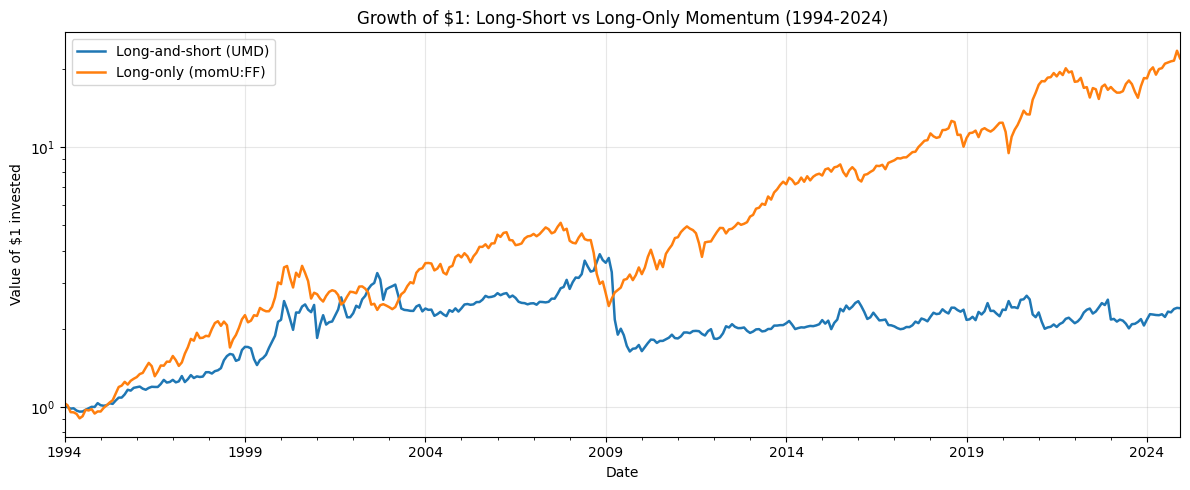

Long-and-short (UMD)     $2.40
Long-only (momU:FF)     $22.02


In [5]:
cumulative = (1 + long_only).cumprod()

fig, ax = plt.subplots(figsize = (12, 5))

cumulative.plot(ax = ax, linewidth = 1.8)

ax.set(title = "Growth of $1: Long-Short vs Long-Only Momentum (1994-2024)", xlabel = "Date", ylabel = "Value of $1 invested")
ax.set_yscale("log")
ax.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

print(cumulative.iloc[-1].map("${:.2f}".format).to_string())

> Over 1994-2024 a dollar in the long-only portfolio grows to about \$22, while a dollar in UMD grows to about \$2.40. The long-only line tracks the equity market's drawdowns (2000-2002, 2008, 2020, 2022). UMD peaks before 2009, falls sharply in the 2009 momentum crash, and roughly goes sideways afterward.

### 2.3. 
Is momentum just data mining, or is it a robust strategy?

Assess how sensitive the threshold for the “winners” and “losers” is in the results. Specifically, we compare three constructions:

- long the top 1 decile and short the bottom 1 deciles:

$$ \tilde{r}^{momD1} = r^{mom(10)} - r^{mom(1)}$$

- long the top 3 deciles and short the bottom 3 deciles:

$$ 
\begin{aligned}
\tilde{r}^{momD3} &= \frac{1}{3}(r^{mom(8)} + r^{mom(9)} + r^{mom(10)}) - \frac{1}{3} (r^{mom(3)} + r^{mom(2)} + r^{mom(1)})\\
&= \frac{1}{3}\sum_{k = 8}^{10} r^{mom(k)} - \frac{1}{3}\sum_{k = 1}^{3} r^{mom(k)} 
\end{aligned}$$

- long the top 5 deciles and short the bottom 5 decile:

$$ \tilde{r}^{momD5} = \frac{1}{5}\sum_{k = 6}^{10} r^{mom(k)} - \frac{1}{5}\sum_{k = 1}^{5} r^{mom(k)} $$

#### (a) 
Compare all three constructions by filling out the stats in the table below for the period 1994-2024.

$$
\begin{equation}
\begin{aligned}
&\text { Table 3: Robustness of momentum construction. }\\
&\begin{array}{lllllll}
\hline \hline \text { 1994-2024 } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skewness } & \text { corr. to } \tilde{r}^m & \text { corr. to } \tilde{r}^v \\
\hline \hline \tilde{r}^{\text {momD1 }} & & & & & & \\
\tilde{r}^{\text {momD3 }} & & & & & & \\
\tilde{r}^{\text {momD5 }} & & & & & & \\
\hline \hline
\end{array}
\end{aligned}
\end{equation}
$$

In [6]:
d = deciles.loc[sample]

robustness = pd.DataFrame({"momD1": d["Hi PRIOR"] - d["Lo PRIOR"],
                           "momD3": d.iloc[:, 7:].mean(axis = 1) - d.iloc[:, :3].mean(axis = 1),
                           "momD5": d.iloc[:, 5:].mean(axis = 1) - d.iloc[:, :5].mean(axis = 1)})

table3 = hw6utils.momentum_summary(robustness, factors.loc[sample])

display(table3.style.format(stats_format))

,Mean,Volatility,Sharpe,Skewness,Corr. to MKT,Corr. to HML
momD1,8.10%,29.96%,0.2703,-1.3012,-0.3242,-0.2375
momD3,2.97%,19.37%,0.1535,-1.3411,-0.3632,-0.2121
momD5,1.73%,13.43%,0.1285,-1.4215,-0.3544,-0.2087


#### (b) 
Do the tradeoffs between the 1-decile, 3-decile, and 5-decile constructions line up with the theoretical tradeoffs we discussed in the lecture?

> Yes. A more extreme sort gives a bigger spread in momentum scores, so it earns a larger mean but holds fewer stocks and is less diversified. Going from 5 deciles to 1 decile, the mean rises from 1.73% to 2.97% to 8.10% and volatility rises from 13.43% to 19.37% to 29.96%. The mean grows faster than the volatility, so the Sharpe ratio also rises (0.13, 0.15, 0.27). Skewness (about −1.3 to −1.4) and the correlations to the market (about −0.35) and value (about −0.21) barely change, so all three are capturing the same factor. The result does not depend on the exact cutoff, which is evidence that momentum is not just data mining.

#### (c) 
Should AQR's retail product consider using a 1-decile or 5-decile construction?

> Neither extreme is a good fit. The 1-decile portfolio has the best Sharpe ratio on paper, but it holds only the most extreme 10% of stocks. Those positions turn over the most, are more concentrated, and its 30% volatility would be hard for retail investors to sit through. The gross Sharpe advantage would shrink once trading costs are included. The 5-decile portfolio holds everything, so it is cheap and diversified, but its signal is so diluted that the premium (1.7% a year) could disappear after fees and costs. A middle construction like the top third, which is what AQR's index uses, is a reasonable compromise between signal strength and diversification and turnover.

#### (d) 
Does $\tilde{r}^{\text {momD3 }}$ have similar stats to the Fama-French construction in (1). Recall that construction is also a 3-decile, long-short construction, but it is segmented for small and large stocks. Compare the middle row of Table 3 with the top row of Table 2.

> They are similar but not identical. Skewness (−1.34 vs −1.46) and the correlations to the market (−0.36 vs −0.31) and value (−0.21 vs −0.21) are close. However, momD3 has a lower mean (2.97% vs 4.31%), higher volatility (19.37% vs 16.72%) and so a lower Sharpe ratio (0.15 vs 0.26). The decile portfolios are value-weighted across all stocks, so they are dominated by large caps. The FF construction puts half its weight on small stocks, where momentum is stronger (see 2.4), and averaging the small and big legs diversifies across size, which lowers volatility.

### 2.4. 
Does implementing momentum require trading lots of small stocks-- thus causing even larger trading costs?

For regulatory and liquidity reasons, AQR is particularly interested in using larger stocks for their momentum baskets. (Though they will launch one product that focuses on medium-sized stocks.)

Use the data provided on both small-stock “winners”, $r^{momSU}$, and small-stock “losers”, $r^{momSD}$, to construct a small-stock momentum portfolio,

$$ r^{momS}_t = r^{momSU}_t - r^{momSD}_t $$

Similarly, use the data provided to construct a big-stock momentum portfolio,

$$ r^{momB}_t = r^{momBU}_t − r^{momBD}_t $$

#### (a) 
Fill out Table 4 over the sample 1994-2024.

$$
\begin{equation*}
\begin{aligned}
&\text { Table 4: Momentum of small and big stocks. }\\
&\begin{array}{llllll}
\hline \hline \text { 1994-2024 } & \text { mean } & \text { vol } & \text { Sharpe } & \text { skewness } & \text { corr. to } \tilde{r}^m \\
\hline \hline \text { All stocks, } \tilde{r}^{\text {mom:FF }} & & & & & \\
\text { Small stocks } r_t^{\text {mom } S} & & & & & \\
\text { Large stocks } r_t^{\text {mom } B} & & & & & \\
\hline
\end{array}
\end{aligned}
\end{equation*}
$$

In [7]:
z = size_sorts.loc[sample]

size_momentum = pd.DataFrame({"All stocks (UMD)": umd.loc[sample],
                              "Small stocks (momS)": z["SMALL HiPRIOR"] - z["SMALL LoPRIOR"],
                              "Large stocks (momB)": z["BIG HiPRIOR"] - z["BIG LoPRIOR"]})

table4 = hw6utils.momentum_summary(size_momentum, factors.loc[sample]).drop(columns = "Corr. to HML")

display(table4.style.format(stats_format))

,Mean,Volatility,Sharpe,Skewness,Corr. to MKT
All stocks (UMD),4.31%,16.72%,0.2575,-1.4610,-0.3105
Small stocks (momS),6.14%,16.91%,0.3631,-1.8042,-0.3102
Large stocks (momB),2.46%,18.23%,0.1351,-0.8745,-0.2819


#### (b) 
Is the attractiveness of the momentum strategy mostly driven by the small stocks? That is, does a momentum strategy in large stocks still deliver excess returns at comparable risk?

> Small stocks drive more of it, but not all. From 1994-2024 small-stock momentum earns 6.14% a year (Sharpe 0.36) versus 2.46% for large stocks (Sharpe 0.14), at similar volatility (16.91% vs 18.23%). Large-stock momentum is still positive, with less negative skewness (−0.87 vs −1.80) and a similar negative market correlation (−0.28 vs −0.31). The two legs are 0.81 correlated, so they are the same effect at different strengths.
>
> So momentum does exist among large stocks, but at about 40% of the premium and with a Sharpe ratio about half of UMD's. That matters for AQR, since the large-cap product gives up much of the small-stock premium in exchange for liquidity and lower trading costs. Small stocks are also more expensive to trade, so part of their gross advantage would be lost to transaction costs.

### 2.5. 
In conclusion, what is your assessment of the AQR retail product? Is it capturing the important features of the Fama-French construction of momentum? Would you suggest any modifications?

> The AQR product captures some features of FF momentum but leaves out several important ones.
>
> * **What it keeps.** It ranks on $t-12$ to $t-2$ returns and buys the top third, the same signal and cutoff as FF. Section 2.3 shows that the premium holds up across cutoffs, so this is a reasonable choice. It also has a positive momentum alpha (about 2.3% a year over the market in 2.2).
> * **What it loses.** Being long-only means it is about 90% correlated with the market, so it loses momentum's main portfolio benefit: the negative correlation with the market and value. It also captures only part of the premium, because the loser side is unavailable. Restricting it to large caps gives up more of the premium (2.4), since large-stock momentum earns about 40% as much as small-stock momentum.
> * **What's improved.** It has much milder negative skewness than UMD (−0.44 vs −1.46), and quarterly rebalancing of liquid large caps keeps trading costs and tracking error manageable for a daily-liquidity fund.
>
> **Suggested modifications:**
> 1. Present it to investors as a momentum-tilted replacement for their core equity (e.g., instead of a growth fund), not as a diversifier, since its risk is mostly market risk.
> 2. Where regulation allows, add a market hedge (e.g., shorting index futures) or a modest short of the losers. That would recover more of UMD's diversification and premium without full long-short leverage.
> 3. Pair it with value (the case's own correlation of −0.30 between UMD and HML suggests this), which helps offset the momentum crashes that follow market rebounds.
> 4. Use buffer zones around the top-third cutoff and trade slowly, so that the costs of trading boundary stocks do not wipe out the modest large-cap premium.